# Zeladoria do Bairro · IA & Machine Learning
**GS CitizenTech 2026.2 · FIAP · Engenharia de Software (3º ano Fev)**

| Item | Descrição |
|---|---|
| Pergunta de ML | Dado um chamado de **tapa-buraco** aberto na cidade de São Paulo (canal, local e dia da semana), ele será **resolvido em até 7 dias**? |
| Tipo de problema | Classificação binária (`resolvido_7d` = 1 ou 0) |
| Cidadão beneficiado | O morador que registra o buraco e quer saber se o chamado será atendido logo |
| Fonte dos dados | SP156 (chamados reais da Prefeitura de SP), Portal de Dados Abertos: https://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156 |
| Licença | Creative Commons CCZero (conforme página do dataset) |
| Período usado | 2024 T4 a 2025 T4 (5 trimestres): treino = 2024 T4, 2025 T1 e 2025 T2; teste = 2025 T3 e 2025 T4 |
| ODS | 11 (cidades e comunidades sustentáveis) e 9 (indústria, inovação e infraestrutura) |

**Como executar:** coloque os 5 CSVs do SP156 na pasta `dados/` (ao lado deste notebook) e use *Run All*. As figuras e tabelas são salvas em `saida/`.

## 1. Configuração
Importa as bibliotecas e define os arquivos de cada trimestre, os serviços que contam como "tapa-buraco" e a correspondência entre os nomes de coluna dos CSVs e os nomes padronizados usados aqui (os arquivos do SP156 mudam de esquema entre trimestres).

In [1]:
import os
import warnings

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.preprocessing import OrdinalEncoder

warnings.filterwarnings("ignore")
SEED = 42
PASTA_DADOS = "dados"
PASTA_SAIDA = "saida"
os.makedirs(f"{PASTA_SAIDA}/figuras", exist_ok=True)

TREINO = ["arquivo-final-4-trim.-2024.csv", "arquivo-final-1-trim-25.csv", "arquivo-final-2-trim-25.csv"]
TESTE = ["arquivo-final-3-trim-25.csv", "arquivo-final-4-trim-25.csv"]
ROTULO = {"arquivo-final-4-trim.-2024.csv": "2024T4", "arquivo-final-1-trim-25.csv": "2025T1",
          "arquivo-final-2-trim-25.csv": "2025T2", "arquivo-final-3-trim-25.csv": "2025T3",
          "arquivo-final-4-trim-25.csv": "2025T4"}

BURACO = {"Tapa-buraco", "Tapa-buraco em faixa exclusiva ou corredor de ônibus"}

# nome da coluna no CSV (minúsculo) -> nome padronizado
ALIAS = {"data de abertura": "abertura", "data de finalização": "final", "status": "status",
         "serviço": "servico", "meio de comunicação": "canal", "prefeitura operacional": "subpref",
         "distrito": "distrito", "latitude": "lat", "longitude": "lon"}

## 2. Leitura e limpeza dos dados
A função lê um CSV (separador `;`, codificação Latin-1, tudo como texto) apenas com as colunas necessárias e aplica a limpeza:
1. fica só com os serviços de tapa-buraco;
2. remove chamados **cancelados** (não são nem resolvidos nem não resolvidos);
3. remove chamados "Finalizada" **sem data de finalização** (não dá para calcular o prazo);
4. converte as datas (dia/mês/ano) e calcula `dias` = finalização − abertura;
5. cria o alvo `resolvido_7d`: 1 se `dias` ≤ 7. Chamados ainda abertos (sem data) viram 0, porque não foram resolvidos em 7 dias.

Também cria variáveis simples conhecidas **no momento da abertura**: dia da semana e se é em corredor de ônibus. `Data de Finalização` e `Status` servem só para montar o alvo e **não entram como variáveis do modelo** (seria vazamento de dados).

In [2]:
def montar(arquivo, divisao):
    df = pd.read_csv(os.path.join(PASTA_DADOS, arquivo), sep=";", encoding="latin-1", dtype=str,
                     usecols=lambda c: c.strip().lower() in ALIAS)
    df = df.rename(columns=lambda c: ALIAS[c.strip().lower()])
    n_lidas = len(df)

    df = df[df["servico"].str.strip().isin(BURACO)].copy()
    n_buraco = len(df)

    df["status"] = df["status"].str.strip().str.lower()
    df = df[df["status"] != "cancelada"]
    n_sem_canceladas = len(df)

    df["abertura"] = pd.to_datetime(df["abertura"], format="%d/%m/%Y", errors="coerce")
    df["final"] = pd.to_datetime(df["final"], format="%d/%m/%Y", errors="coerce")
    df = df[~((df["status"] == "finalizada") & df["final"].isna())]

    df["dias"] = (df["final"] - df["abertura"]).dt.days
    df["resolvido_7d"] = (df["dias"] <= 7).astype(int)
    df["dia_semana"] = df["abertura"].dt.dayofweek          # 0 = segunda-feira
    df["corredor"] = (df["servico"].str.strip() != "Tapa-buraco").astype(int)
    df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
    df["lon"] = pd.to_numeric(df["lon"], errors="coerce")
    df["divisao"] = divisao
    df["trimestre"] = ROTULO[arquivo]

    resumo = {"trimestre": ROTULO[arquivo], "divisao": divisao, "linhas_no_arquivo": n_lidas,
              "tapa_buraco": n_buraco, "sem_canceladas": n_sem_canceladas,
              "sem_finalizadas_sem_data": len(df)}
    colunas = ["trimestre", "divisao", "abertura", "dia_semana", "canal", "subpref", "distrito",
               "lat", "lon", "corredor", "dias", "resolvido_7d"]
    return df[colunas], resumo


partes, resumos = [], []
for arq in TREINO:
    d, r = montar(arq, "treino"); partes.append(d); resumos.append(r)
for arq in TESTE:
    d, r = montar(arq, "teste"); partes.append(d); resumos.append(r)

dados = pd.concat(partes, ignore_index=True)
print(pd.DataFrame(resumos).to_string(index=False))
print("\nDataset do modelo:", dados.shape)
dados.head()

trimestre divisao  linhas_no_arquivo  tapa_buraco  sem_canceladas  sem_finalizadas_sem_data
   2024T4  treino             576794        21431           21392                     21224
   2025T1  treino            1048575        33384           33191                     33191
   2025T2  treino             589980        32494           32319                     32314
   2025T3   teste             501685        26693           26597                     26591
   2025T4   teste             479701        23297           23212                     23204

Dataset do modelo: (136524, 12)


,trimestre,divisao,abertura,dia_semana,canal,subpref,distrito,lat,lon,corredor,dias,resolvido_7d
0,2024T4,treino,2024-11-14,3,PORTAL,Superintendencia das Usinas de Asfalto,CAMPO BELO,-23.612989,-46.670421,0,159.0,0
1,2024T4,treino,2024-11-07,3,MOBILE,SAO MIGUEL,JARDIM HELENA,-23.482442,-46.384792,0,1.0,1
2,2024T4,treino,2024-11-07,3,MOBILE,IPIRANGA,SACOMA,-23.608477,-46.601899,0,25.0,0
3,2024T4,treino,2024-11-18,0,MOBILE,SAO MATEUS,SAO RAFAEL,-23.619209,-46.466428,0,8.0,0
4,2024T4,treino,2024-11-18,0,CRM,PENHA,VILA MATILDE,-23.535845,-46.508276,0,0.0,1


## 3. Por que estes trimestres? (decisões sobre os dados)
Antes de escolher o período, o resumo de **10 trimestres** (2024 T1 a 2026 T3) mostrou que nem todos servem. Valores para tapa-buraco, em % dos chamados não cancelados (abertos contam como "não resolvido em 7 dias"):

| Trimestre | % ainda abertos | % resolvidos em até 7 dias | Mediana de dias | Decisão |
|---|---|---|---|---|
| 2024 T1 | 0,7 | 29,0 | 30 | fora (serviço em outro patamar) |
| 2024 T3 | 22,9 | 33,3 | 10 | fora (muitos chamados abertos 2 anos depois, provável resíduo de sistema) |
| **2024 T4** | 1,0 | 40,7 | 11 | **treino** |
| **2025 T1** | 0,9 | 47,9 | 8 | **treino** |
| **2025 T2** | 1,6 | 56,1 | 6 | **treino** |
| **2025 T3** | 2,8 | 65,1 | 5 | **teste** |
| **2025 T4** | 6,5 | 57,7 | 5 | **teste** |
| 2026 T1 a T3 | 25 a 32 | 27 a 46 | 4 a 14 | fora (muitos chamados ainda abertos; o T3 também mudou de formato de arquivo) |

O 2024 T2 foi descartado porque o arquivo não traz a coluna `Serviço` com o nome esperado.

**Outras decisões:** iluminação pública (prevista no plano da solução) **não existe** como serviço no SP156; entulho e limpeza de bueiros foram avaliados, mas fecham em até 7 dias em 85% a 100% dos casos, o que deixaria a pergunta trivial. O foco ficou no tapa-buraco, que varia de verdade (mediana de 5 a 11 dias entre os trimestres escolhidos).

A figura abaixo mostra a taxa de resolução em 7 dias nos 5 trimestres usados: o serviço **melhorou ao longo do tempo**, e isso afeta a avaliação.

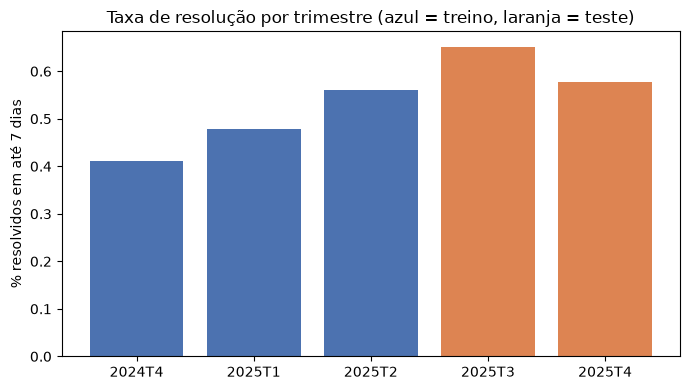

trimestre
2024T4    0.410
2025T1    0.479
2025T2    0.561
2025T3    0.651
2025T4    0.577
Name: resolvido_7d, dtype: float64


In [3]:
taxa = dados.groupby("trimestre")["resolvido_7d"].mean()
cores = ["#4c72b0" if t in {"2024T4", "2025T1", "2025T2"} else "#dd8452" for t in taxa.index]

plt.figure(figsize=(7, 4))
plt.bar(taxa.index, taxa.values, color=cores)
plt.ylabel("% resolvidos em até 7 dias")
plt.title("Taxa de resolução por trimestre (azul = treino, laranja = teste)")
plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/figuras/1_taxa_por_trimestre.png", dpi=150)
plt.show()
print(taxa.round(3))

## 4. Preparação e divisão treino/teste
- **Coordenadas fora do município** (erro de geocodificação) são removidas com um retângulo aproximado de São Paulo.
- Valores vazios nas variáveis de texto viram `"desconhecido"`.
- **A divisão é por tempo, não aleatória**: o treino usa os trimestres mais antigos e o teste, os mais novos. Chamados repetidos do mesmo buraco são quase idênticos; numa divisão aleatória um iria para o treino e o "gêmeo" para o teste, e a métrica sairia inflada. Separar por período simula o uso real: o modelo prevê chamados de um período que ele nunca viu.
- O `OrdinalEncoder` transforma as categorias (canal, subprefeitura, distrito) em números e é ajustado **só no treino**; categoria nova no teste vira `-1`.
- O mês **não** é usado como variável: treino e teste cobrem meses diferentes do ano, e o modelo veria meses que nunca treinou.

In [4]:
dentro = dados["lat"].between(-24.01, -23.35) & dados["lon"].between(-46.84, -46.30)
print("Pontos fora do município removidos:", (~dentro).sum(), "de", len(dados))
dados = dados[dentro].copy()

CATEG = ["canal", "subpref", "distrito"]
NUM = ["dia_semana", "corredor", "lat", "lon"]
dados[CATEG] = dados[CATEG].fillna("desconhecido")

treino = dados[dados["divisao"] == "treino"].copy()
teste = dados[dados["divisao"] == "teste"].copy()
teste["subpref_nome"] = teste["subpref"]          # guarda o nome para a análise por região

enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
treino[CATEG] = enc.fit_transform(treino[CATEG])
teste[CATEG] = enc.transform(teste[CATEG])

COLUNAS = CATEG + NUM
X_tr, y_tr = treino[COLUNAS], treino["resolvido_7d"]
X_te, y_te = teste[COLUNAS], teste["resolvido_7d"]

print(f"Treino: {len(X_tr)} linhas | % resolvidos em 7 dias: {y_tr.mean():.3f}")
print(f"Teste:  {len(X_te)} linhas | % resolvidos em 7 dias: {y_te.mean():.3f}")

Pontos fora do município removidos: 23 de 136524
Treino: 86710 linhas | % resolvidos em 7 dias: 0.493
Teste:  49791 linhas | % resolvidos em 7 dias: 0.617


## 5. Escolha do modelo: Random Forest
- Funciona bem com variáveis mistas (categorias codificadas e números) e captura relações não lineares, como "região x tipo de via", sem exigir normalização.
- É robusto a ruído e a variáveis pouco informativas, o que importa aqui: temos poucas variáveis e dados reais e bagunçados.
- Tem poucos hiperparâmetros sensíveis e treina rápido, o que permite uma busca com validação cruzada em poucos minutos.
- Dá a **importância das variáveis**, necessária para explicar o resultado ao cidadão.
- O XGBoost é da mesma família (árvores) e seria uma alternativa; ficou como melhoria futura.

Primeiro, um **baseline**: a regra "sempre prever a classe mais comum do treino". Se o modelo não bater o baseline, ele não aprendeu nada útil.

In [5]:
maioria = int(y_tr.mean() >= 0.5)
print(f"Classe mais comum no treino: {maioria}")
print(f"Baseline - acurácia no treino: {(y_tr == maioria).mean():.3f} | no teste: {(y_te == maioria).mean():.3f}")
print(f"Para comparar: prever sempre 'sim' no teste daria {y_te.mean():.3f}")

Classe mais comum no treino: 0
Baseline - acurácia no treino: 0.507 | no teste: 0.383
Para comparar: prever sempre 'sim' no teste daria 0.617


## 6. Treino com diferentes hiperparâmetros
Busca em grade (`GridSearchCV`) com **12 combinações de 3 hiperparâmetros** (2 × 3 × 2):
- `n_estimators` (quantidade de árvores): 100 ou 200;
- `max_depth` (profundidade máxima): 6, 12 ou 20;
- `min_samples_leaf` (mínimo de amostras por folha): 5 ou 20.

A **validação cruzada usa só o treino**, com um fold por trimestre (`GroupKFold`): cada rodada valida num trimestre que o modelo não viu, o que evita chamados repetidos dos dois lados. O critério é a **AUC** (capacidade de ordenar os chamados do mais para o menos provável de resolver rápido, sem depender de um limiar). `mean_train_score` muito acima de `mean_test_score` indica overfitting.

 param_n_estimators  param_max_depth  param_min_samples_leaf  mean_train_score  mean_test_score  std_test_score
                200               12                       5             0.778            0.665           0.032
                100               12                       5             0.777            0.664           0.032
                200               12                      20             0.749            0.663           0.033
                100               12                      20             0.749            0.663           0.033
                200               20                      20             0.787            0.662           0.032
                100               20                      20             0.786            0.662           0.032
                200               20                       5             0.887            0.657           0.030
                100               20                       5             0.886            0.656         

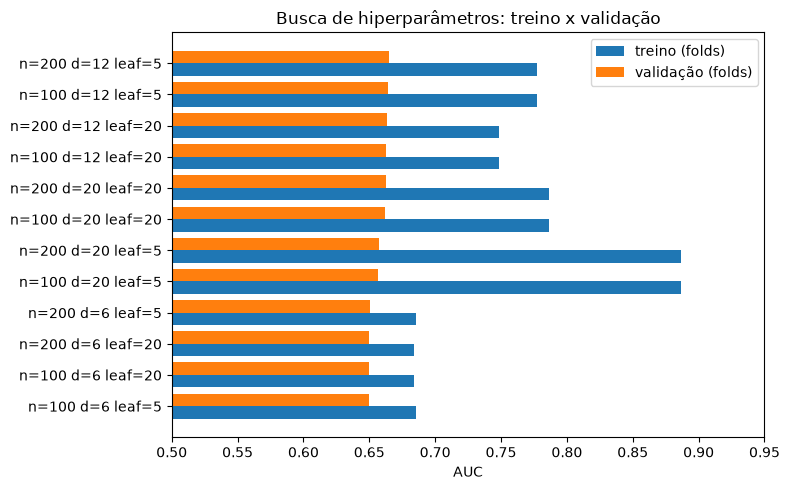

In [6]:
grade = {"n_estimators": [100, 200], "max_depth": [6, 12, 20], "min_samples_leaf": [5, 20]}

busca = GridSearchCV(RandomForestClassifier(random_state=SEED, n_jobs=-1), grade,
                     scoring="roc_auc", cv=GroupKFold(n_splits=3),
                     return_train_score=True, refit=True)
busca.fit(X_tr, y_tr, groups=treino["trimestre"])

cv = pd.DataFrame(busca.cv_results_)[["param_n_estimators", "param_max_depth", "param_min_samples_leaf",
                                       "mean_train_score", "mean_test_score", "std_test_score"]]
cv = cv.sort_values("mean_test_score", ascending=False)
cv.to_csv(f"{PASTA_SAIDA}/cv_resultados.csv", index=False)
print(cv.round(3).to_string(index=False))
print("\nMelhores parâmetros:", busca.best_params_)

# Figura: AUC de treino x validação por combinação
g = cv.sort_values("mean_test_score").copy()
g["combo"] = ("n=" + g["param_n_estimators"].astype(str) + " d=" + g["param_max_depth"].astype(str)
              + " leaf=" + g["param_min_samples_leaf"].astype(str))
y = range(len(g))
plt.figure(figsize=(8, 5))
plt.barh([i - 0.2 for i in y], g["mean_train_score"], height=0.4, label="treino (folds)")
plt.barh([i + 0.2 for i in y], g["mean_test_score"], height=0.4, label="validação (folds)")
plt.yticks(list(y), g["combo"]); plt.xlim(0.5, 0.95); plt.xlabel("AUC"); plt.legend()
plt.title("Busca de hiperparâmetros: treino x validação")
plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/figuras/2_busca_hiperparametros.png", dpi=150)
plt.show()

## 7. Resultados em treino e teste
O melhor modelo da busca (já reajustado em todo o treino) é avaliado no treino e no teste, lado a lado, com limiar 0,5:
- **precisão**: de tudo que o modelo previu como "resolve em 7 dias", quanto realmente resolveu;
- **revocação**: de tudo que realmente resolveu em 7 dias, quanto o modelo encontrou;
- **AUC**: 0,5 equivale ao acaso e 1,0 é perfeito.

Como a taxa de resolução subiu do treino para o teste, a acurácia sozinha engana (prever sempre "sim" daria 0,617 no teste). Por isso a AUC é a métrica principal.

conjunto  acuracia  precisao  revocacao    f1   auc  pct_previsto_sim  pct_real_sim
  treino     0.679     0.666      0.700 0.683 0.763             0.518         0.493
   teste     0.564     0.664      0.596 0.628 0.573             0.554         0.617

Matriz de confusão no teste (linhas = real 0/1, colunas = previsto 0/1):
[[ 9808  9271]
 [12415 18297]]


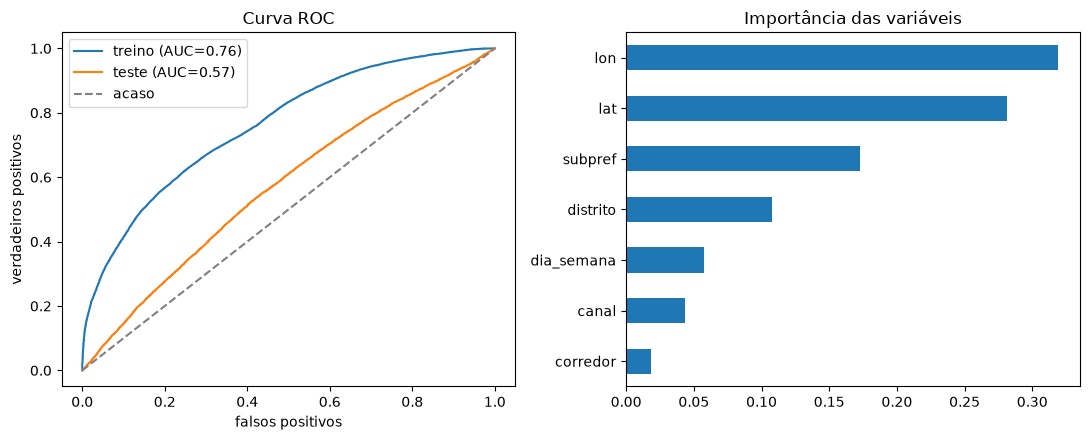

lon           0.319
lat           0.281
subpref       0.173
distrito      0.107
dia_semana    0.057
canal         0.043
corredor      0.019
dtype: float64


In [7]:
modelo = busca.best_estimator_
p_tr = modelo.predict_proba(X_tr)[:, 1]
p_te = modelo.predict_proba(X_te)[:, 1]

linhas = []
for nome, y_real, p in [("treino", y_tr, p_tr), ("teste", y_te, p_te)]:
    pred = (p >= 0.5).astype(int)
    linhas.append({"conjunto": nome, "acuracia": accuracy_score(y_real, pred),
                   "precisao": precision_score(y_real, pred), "revocacao": recall_score(y_real, pred),
                   "f1": f1_score(y_real, pred), "auc": roc_auc_score(y_real, p),
                   "pct_previsto_sim": pred.mean(), "pct_real_sim": y_real.mean()})
metricas = pd.DataFrame(linhas).round(3)
metricas.to_csv(f"{PASTA_SAIDA}/metricas_finais.csv", index=False)
print(metricas.to_string(index=False))

print("\nMatriz de confusão no teste (linhas = real 0/1, colunas = previsto 0/1):")
print(confusion_matrix(y_te, (p_te >= 0.5).astype(int)))

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5))
for nome, y_real, p in [("treino", y_tr, p_tr), ("teste", y_te, p_te)]:
    fpr, tpr, _ = roc_curve(y_real, p)
    eixos[0].plot(fpr, tpr, label=f"{nome} (AUC={roc_auc_score(y_real, p):.2f})")
eixos[0].plot([0, 1], [0, 1], "--", color="gray", label="acaso")
eixos[0].set_xlabel("falsos positivos"); eixos[0].set_ylabel("verdadeiros positivos")
eixos[0].set_title("Curva ROC"); eixos[0].legend()

imp = pd.Series(modelo.feature_importances_, index=COLUNAS).sort_values()
imp.plot.barh(ax=eixos[1]); eixos[1].set_title("Importância das variáveis")
plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/figuras/3_roc_e_importancia.png", dpi=150)
plt.show()
print(imp.sort_values(ascending=False).round(3))

## 8. Leitura para o cidadão: onde o buraco costuma demorar mais?
O modelo erra o **nível geral** no teste (o serviço melhorou), mas pode acertar a **ordem entre regiões**. A tabela compara, por subprefeitura (com pelo menos 300 chamados no teste), a probabilidade média prevista com a taxa real de resolução em 7 dias. A correlação de Spearman mede se a ordem das regiões bate.

                              n  real  previsto
subpref_nome                                   
PIRITUBA-JARAGUA           2196  0.48      0.35
LAPA                       1462  0.49      0.39
CIDADE TIRADENTES           410  0.52      0.55
BUTANTA                    3483  0.53      0.36
VILA MARIANA               1597  0.53      0.34
PERUS                       998  0.54      0.48
CAMPO LIMPO                3152  0.56      0.36
ARICANDUVA-FORMOSA-CARRAO  2316  0.57      0.64
PENHA                      3003  0.58      0.36
PINHEIROS                  1745  0.59      0.37
ITAIM PAULISTA             2289  0.60      0.25
SE                         1438  0.61      0.51
IPIRANGA                   1476  0.63      0.52
SAO MIGUEL                 1420  0.63      0.37
CIDADE ADEMAR               934  0.63      0.61
ERMELINO MATARAZZO         1078  0.64      0.50
ITAQUERA                   2830  0.64      0.57
SAO MATEUS                 3414  0.65      0.60
M BOI MIRIM                1170  0.66   

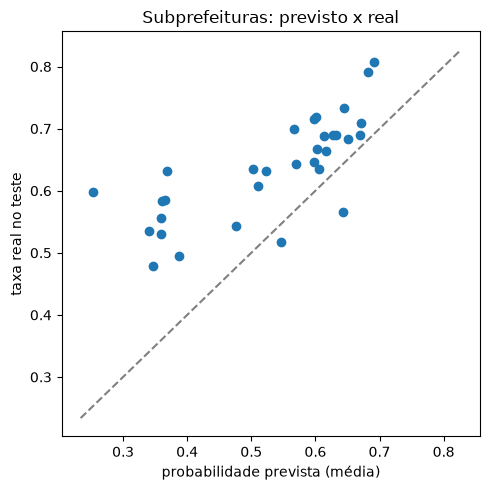

In [8]:
teste["prob"] = p_te
sub = (teste.groupby("subpref_nome")
       .agg(n=("resolvido_7d", "size"), real=("resolvido_7d", "mean"), previsto=("prob", "mean"))
       .query("n >= 300").sort_values("real"))
print(sub.round(2).to_string())
rho = sub["previsto"].corr(sub["real"], method="spearman")
print(f"\nCorrelação de Spearman (previsto x real): {rho:.2f}")

plt.figure(figsize=(5, 5))
plt.scatter(sub["previsto"], sub["real"])
lim = [min(sub["real"].min(), sub["previsto"].min()) - 0.02, max(sub["real"].max(), sub["previsto"].max()) + 0.02]
plt.plot(lim, lim, "--", color="gray")
plt.xlabel("probabilidade prevista (média)"); plt.ylabel("taxa real no teste")
plt.title("Subprefeituras: previsto x real")
plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/figuras/4_subprefeituras.png", dpi=150)
plt.show()

## 9. Conclusão
- **O modelo aprende algo, mas pouco.** No teste, a AUC é 0,573 (0,5 = acaso), contra 0,763 no treino e 0,665 na validação cruzada. A precisão no teste (0,664) é só um pouco maior que a taxa real de resolvidos (0,617).
- **Overfitting moderado e mudança de regime.** A queda do treino para o teste tem duas causas: o modelo se ajusta ao treino, e o serviço **melhorou** entre os períodos (resolvidos em 7 dias: 49% no treino, 62% no teste; mediana de 11 para 5 dias), então o modelo treinado numa fila mais lenta subestima a rapidez no teste.
- **Localização é o que mais pesa** (`lon`, `lat`, `subpref`, `distrito`). Dia da semana e canal contribuem pouco.
- **Tentativa que não melhorou:** acrescentar a demanda recente (chamados dos 7 dias anteriores no distrito e na cidade) deu AUC no teste de 0,567 (variáveis originais + demanda) e 0,549 (demanda sem coordenadas), contra 0,571 do conjunto original, e piorou a validação cruzada. Mantivemos o conjunto original.
- **Para o cidadão:** o modelo é fraco para dizer se **um chamado específico** será resolvido em 7 dias, e não deve ser usado para prometer prazo a um morador. Ele é mais útil para mostrar **em quais regiões** os buracos tendem a demorar mais: a ordem entre subprefeituras bate razoavelmente com a realidade (Spearman acima de 0,7 no teste), com Jabaquara, Jaçanã-Tremembé e Casa Verde entre as mais rápidas e Pirituba-Jaraguá, Lapa e Cidade Tiradentes entre as mais lentas.
- **Limitações:** só 7 variáveis (não sabemos o tamanho do buraco nem a fila da equipe); o status pode estar desatualizado; chamados repetidos do mesmo buraco; e os trimestres de 2026 não puderam ser usados por terem muitos chamados em aberto. **Próximos passos:** dados de chuva (INMET), tipo de via e acompanhamento contínuo do tempo de resolução.